In [1]:
install.packages("tidyverse")
install.packages("eurostat")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘proxy’, ‘e1071’, ‘plyr’, ‘bibtex’, ‘assertthat’, ‘here’, ‘classInt’, ‘countrycode’, ‘ISOweek’, ‘RefManageR’, ‘regions’




In [2]:
library(tidyverse)
library(eurostat)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.2.1     ✔ readr     2.2.0
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.3     ✔ tibble    3.3.1
✔ lubridate 1.9.5     ✔ tidyr     1.3.2
✔ purrr     1.2.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [4]:
results <- search_eurostat("accidents")
print(results)

# A tibble: 61 × 9
   title       code  type  last.update.of.data last.table.structure…¹ data.start
   <chr>       <chr> <chr> <chr>               <chr>                  <chr>     
 1 Victims in… tran… data… 25.03.2026          04.03.2026             1990      
 2 Persons ki… enps… data… 05.03.2026          05.03.2026             2005      
 3 Road accid… med_… data… 28.05.2020          10.01.2024             2005      
 4 Deaths rel… hlth… data… 14.04.2026          10.11.2025             2011      
 5 Detailed d… hlth… data… 13.03.2026          13.03.2026             2011      
 6 Accidents … hsw_… data… 26.03.2026          14.10.2025             2008      
 7 Non-fatal … hsw_… data… 16.04.2026          26.06.2025             2008      
 8 Non-fatal … hsw_… data… 16.04.2026          26.06.2025             2008      
 9 Number of … hsw_… data… 27.03.2009          03.01.2024             2005      
10 Incidence … hsw_… data… 27.03.2009          03.01.2024             2005      
# ℹ 51 mo

In [5]:
results

title,code,type,last.update.of.data,last.table.structure.change,data.start,data.end,values,hierarchy
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
Victims in road accidents by NUTS 2 region,tran_r_acci,dataset,25.03.2026,04.03.2026,1990,2024,56303,5
Persons killed in road accidents - ENP-South countries,enps_tran_sf_r,dataset,05.03.2026,05.03.2026,2005,2025,170,6
Road accidents: persons killed,med_rd7,dataset,28.05.2020,10.01.2024,2005,2018,109,6
Deaths related to transport accidents occurring in the country,hlth_cd_tro,dataset,14.04.2026,10.11.2025,2011,2024,19045,5
Detailed deaths related to transport accidents occurring in the EU,hlth_cd_troeu,dataset,13.03.2026,13.03.2026,2011,2023,6230,5
"Accidents at work of employees by sex and age, excluding road traffic accidents and accidents on board of any mean of transport in the course of work (NACE Rev. 2 activity A, C-N excluding H)",hsw_mi03,dataset,26.03.2026,14.10.2025,2008,2023,136346,6
Non-fatal accidents at work by NACE Rev. 2 activity and sex,hsw_n2_01,dataset,16.04.2026,26.06.2025,2008,2023,425450,6
Non-fatal accidents at work by NACE Rev. 2 activity and age,hsw_n2_03,dataset,16.04.2026,26.06.2025,2008,2023,1270037,6
"Number of accidents at work by contact - mode of injury, NACE Rev. 1.1 activity, sex, age and severity",hsw_aw_co1,dataset,27.03.2009,03.01.2024,2005,2005,498,6


In [6]:
data <- get_eurostat("tran_sf_roadve")

Table tran_sf_roadve cached at /tmp/Rtmp3hBT5l/eurostat/06cc707122bef81e2d7defb1915de281.rds



In [7]:
print(data)
# Display the first few rows of the loaded data
head(data)

# A tibble: 21,467 × 6
   freq  unit  vehicle geo   TIME_PERIOD values
   <chr> <chr> <chr>   <chr> <date>       <dbl>
 1 A     NR    ANI_RD  AT    1999-01-01       0
 2 A     NR    ANI_RD  AT    2000-01-01       0
 3 A     NR    ANI_RD  AT    2001-01-01       0
 4 A     NR    ANI_RD  AT    2002-01-01       0
 5 A     NR    ANI_RD  AT    2003-01-01       0
 6 A     NR    ANI_RD  AT    2004-01-01       0
 7 A     NR    ANI_RD  AT    2005-01-01       0
 8 A     NR    ANI_RD  AT    2006-01-01       0
 9 A     NR    ANI_RD  AT    2007-01-01       0
10 A     NR    ANI_RD  AT    2008-01-01       0
# ℹ 21,457 more rows


freq,unit,vehicle,geo,TIME_PERIOD,values
<chr>,<chr>,<chr>,<chr>,<date>,<dbl>
A,NR,ANI_RD,AT,1999-01-01,0
A,NR,ANI_RD,AT,2000-01-01,0
A,NR,ANI_RD,AT,2001-01-01,0
A,NR,ANI_RD,AT,2002-01-01,0
A,NR,ANI_RD,AT,2003-01-01,0
A,NR,ANI_RD,AT,2004-01-01,0


Certainly! Here are the column names from the data table and what they represent:

freq: This typically refers to the frequency of the data collection, such as 'A' for annual data.
unit: This indicates the unit of measurement for the values column, for example, 'NR' might stand for 'Number'.<br>
vehicle: This dimension likely categorizes the type of vehicle involved in the accidents, such as 'ANI_RD' (animals on road) or other specific vehicle types.<br>
geo: This represents the geographical region (NUTS 2 region in this case) where the accidents occurred, e.g., 'AT' for Austria or specific regional codes.<br>
TIME_PERIOD: This is the date or time period to which the data point corresponds, usually annual in this dataset.<br>
values: This column contains the actual data values, which in this context, would be the number of victims in road accidents.

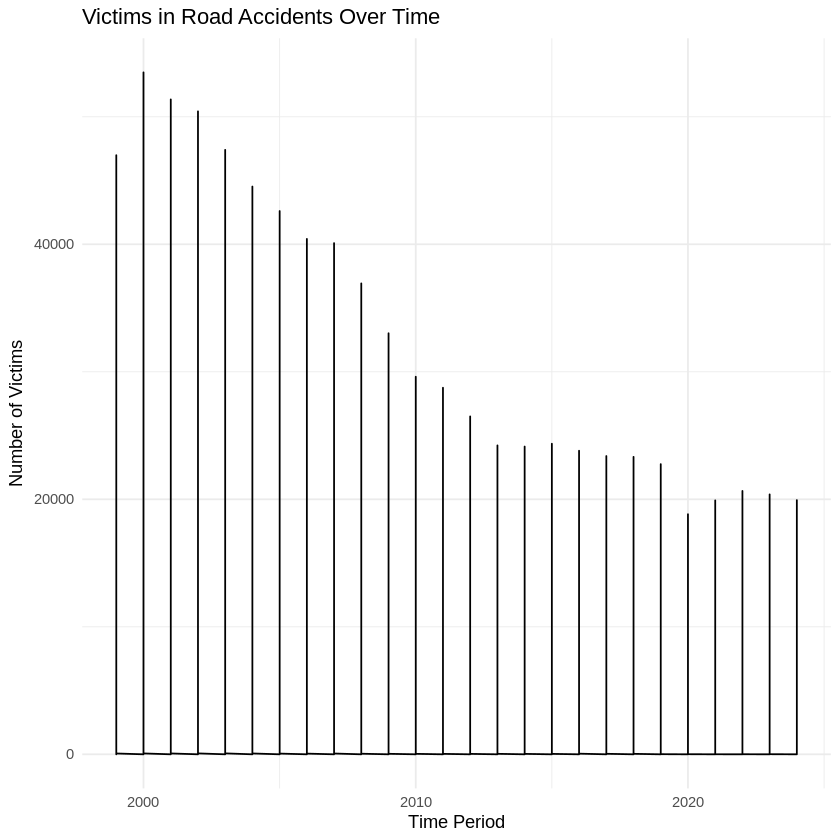

In [8]:
ggplot(data, aes(x = TIME_PERIOD, y = values)) +
  geom_line() +
  labs(title = "Victims in Road Accidents Over Time",
       x = "Time Period",
       y = "Number of Victims") +
  theme_minimal()

In [19]:
new_data <- get_eurostat(id="tgs00061", time_format="num")
new_data <- new_data %>% filter(geo %in% c("AT32", "AT33"))
print(head(new_data))

Dataset query already saved in cache_list.json...

Reading cache file /tmp/Rtmp3hBT5l/eurostat/44af5aaaa80d5275803210450a76d34e.rds

Table  tgs00061  read from cache file:  /tmp/Rtmp3hBT5l/eurostat/44af5aaaa80d5275803210450a76d34e.rds



# A tibble: 6 × 8
  freq  unit  sex   age   icd10 geo   TIME_PERIOD values
  <chr> <chr> <chr> <chr> <chr> <chr>       <dbl>  <dbl>
1 A     RT    T     TOTAL V_Y85 AT32         2013   8.49
2 A     RT    T     TOTAL V_Y85 AT32         2014   7.58
3 A     RT    T     TOTAL V_Y85 AT32         2015   6.21
4 A     RT    T     TOTAL V_Y85 AT32         2016   6.08
5 A     RT    T     TOTAL V_Y85 AT32         2017   6.63
6 A     RT    T     TOTAL V_Y85 AT32         2018   5.95


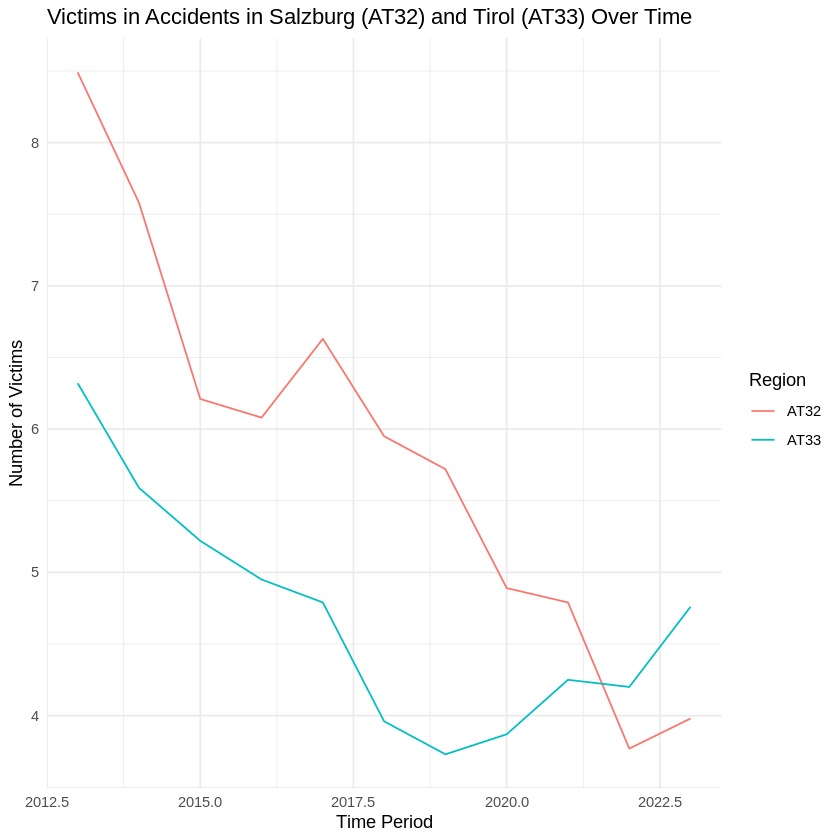

In [20]:
ggplot(new_data, aes(x = TIME_PERIOD, y = values, color = geo)) +
  geom_line() +
  labs(title = "Victims in Accidents in Salzburg (AT32) and Tirol (AT33) Over Time",
       x = "Time Period",
       y = "Number of Victims",
       color = "Region") +
  theme_minimal()

In [24]:
fertility_data <- get_eurostat("demo_frate")

Table demo_frate cached at /tmp/Rtmp3hBT5l/eurostat/87b395eeee209b21c50fa1d39fa09e14.rds



In [25]:
head(fertility_data)

freq,unit,age,agedef,geo,TIME_PERIOD,values
<chr>,<chr>,<chr>,<chr>,<chr>,<date>,<dbl>
A,NR,TOTAL,COMPLET,AD,2006-01-01,1.23598
A,NR,TOTAL,COMPLET,AD,2007-01-01,1.17811
A,NR,TOTAL,COMPLET,AD,2008-01-01,1.25228
A,NR,TOTAL,COMPLET,AD,2009-01-01,1.19414
A,NR,TOTAL,COMPLET,AD,2010-01-01,1.27491
A,NR,TOTAL,COMPLET,AL,2002-01-01,1.90345


In [26]:
unique_dims <- sapply(fertility_data, function(x) length(unique(x)))
print(unique_dims)

# Display unique values for 'indic_de' if it exists, to confirm Total Fertility Rate
if ('indic_de' %in% colnames(fertility_data)) {
  print(unique(fertility_data$indic_de))
}

# Display unique values for 'geo' to see country codes
print(unique(fertility_data$geo))

# Display the range of TIME_PERIOD
print(range(fertility_data$TIME_PERIOD))

       freq        unit         age      agedef         geo TIME_PERIOD 
          1           1          45           1          57          65 
     values 
      18696 
 [1] "AD"         "AL"         "AM"         "AT"         "AZ"        
 [6] "BE"         "BG"         "BY"         "CH"         "CY"        
[11] "CZ"         "DE"         "DE_TOT"     "DK"         "EA20"      
[16] "EA21"       "EE"         "EEA30_2007" "EEA31"      "EFTA"      
[21] "EL"         "ES"         "EU27_2007"  "EU27_2020"  "EU28"      
[26] "FI"         "FR"         "FX"         "GE"         "HR"        
[31] "HU"         "IE"         "IS"         "IT"         "LI"        
[36] "LT"         "LU"         "LV"         "MD"         "ME"        
[41] "MK"         "MT"         "NL"         "NO"         "PL"        
[46] "PT"         "RO"         "RS"         "RU"         "SE"        
[51] "SI"         "SK"         "SM"         "TR"         "UA"        
[56] "UK"         "XK"        
[1] "1960-01-01" "2024-01-0

In [27]:
unique_ages <- unique(fertility_data$age)
print(unique_ages)

# Identify the latest year
latest_year <- max(fertility_data$TIME_PERIOD)

# Filter for the latest year, total age group (assuming 'TOTAL' or similar), and individual countries
# We'll assume 'TOTAL' for now, but will adjust if unique_ages shows a different value
# Also filter out known aggregate 'geo' codes

# List of known aggregate geo codes to exclude (can be expanded if needed)
exclude_geo <- c("EA18", "EA19", "EA20", "EA21", "EU27_2007", "EU27_2020", "EU28", "EFTA", "DE_TOT", "FX", "EEA30_2007", "EEA31")

filtered_fertility_data <- fertility_data %>%
  filter(TIME_PERIOD == latest_year) %>%
  filter(age == "TOTAL") %>% # Assuming 'TOTAL' represents the overall age group
  filter(!geo %in% exclude_geo)

# Check the structure of the filtered data
head(filtered_fertility_data)


 [1] "TOTAL"  "Y10-14" "Y15"    "Y15-19" "Y16"    "Y17"    "Y18"    "Y19"   
 [9] "Y20"    "Y20-24" "Y21"    "Y22"    "Y23"    "Y24"    "Y25"    "Y25-29"
[17] "Y26"    "Y27"    "Y28"    "Y29"    "Y30"    "Y30-34" "Y31"    "Y32"   
[25] "Y33"    "Y34"    "Y35"    "Y35-39" "Y36"    "Y37"    "Y38"    "Y39"   
[33] "Y40"    "Y40-44" "Y41"    "Y42"    "Y43"    "Y44"    "Y45"    "Y45-49"
[41] "Y46"    "Y47"    "Y48"    "Y49"    "Y_GE50"


freq,unit,age,agedef,geo,TIME_PERIOD,values
<chr>,<chr>,<chr>,<chr>,<chr>,<date>,<dbl>
A,NR,TOTAL,COMPLET,AL,2024-01-01,1.64315
A,NR,TOTAL,COMPLET,AT,2024-01-01,1.31126
A,NR,TOTAL,COMPLET,BE,2024-01-01,1.44389
A,NR,TOTAL,COMPLET,BG,2024-01-01,1.71886
A,NR,TOTAL,COMPLET,CH,2024-01-01,1.28745
A,NR,TOTAL,COMPLET,CY,2024-01-01,1.38098



Country with the highest fertility rate:
# A tibble: 1 × 2
  geo   values
  <chr>  <dbl>
1 ME      1.75

Country with the lowest fertility rate:
# A tibble: 1 × 2
  geo   values
  <chr>  <dbl>
1 MT      1.01


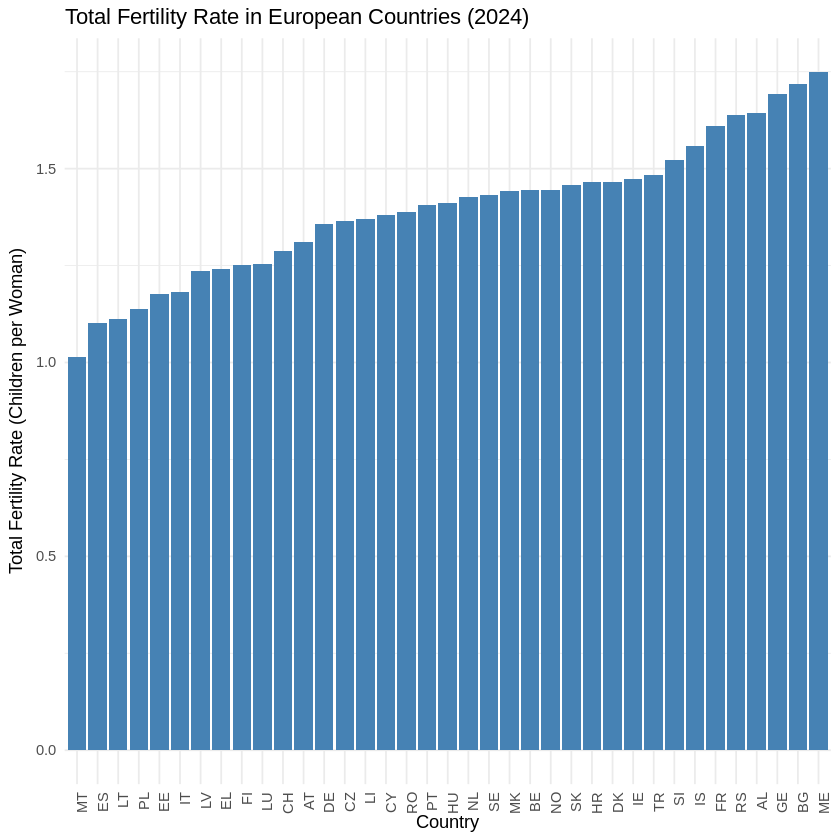

In [28]:
# Create a bar chart of fertility rates per country
ggplot(filtered_fertility_data, aes(x = reorder(geo, values), y = values)) +
  geom_col(fill = "steelblue") +
  labs(title = paste0("Total Fertility Rate in European Countries (", format(latest_year, "%Y"), ")"),
       x = "Country",
       y = "Total Fertility Rate (Children per Woman)") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1))

# Find the country with the highest fertility rate
max_fertility_country <- filtered_fertility_data %>%
  filter(values == max(values)) %>%
  select(geo, values)

# Find the country with the lowest fertility rate
min_fertility_country <- filtered_fertility_data %>%
  filter(values == min(values)) %>%
  select(geo, values)

cat("\nCountry with the highest fertility rate:\n")
print(max_fertility_country)

cat("\nCountry with the lowest fertility rate:\n")
print(min_fertility_country)